In [1]:
from time import time

import numpy as np
from mandelbrot import mandelbrot_matrix, mandelbrot_vec_double, mandelbrot_vec_single
from numba import jit, prange

In [2]:
def mandelbrot_vec_double(x, y, maxiter=100):
    mat = np.zeros((x.size, y.size))

    for i in prange(x.size):
        # if i % 1000 == 0:
        #     print(i+1, x.size)
        for j in range(y.size):
            c = complex(x[i], y[j])
            z = complex(0, 0)

            for n in range(maxiter):
                z = z * z + c
                if z.real * z.real + z.imag * z.imag > 4.0:
                    mat[i, j] = n + 1 - np.log(np.log(np.abs(z * z + c))) / np.log(2)
                    # mat[i, j] = n + 1
                    break
    return mat

In [3]:
def mandelbrot_matrix(x, y, maxiter=100):
    mat = np.zeros(x.size)

    for i in prange(x.size):
        # print(i, x.size)
        c = complex(x[i], y[i])
        z = complex(0, 0)

        for n in range(maxiter):
            z = z * z + c
            if z.real * z.real + z.imag * z.imag > 4.0:
                mat[i] = n + 1 - np.log(np.log(np.abs(z * z + c))) / np.log(2)
                break

    return mat

In [35]:
def mandelbrot_vec_single(x, y, maxiter=100):
    mat = np.zeros((x.size, y.size))

    for k in prange(x.size * y.size):
        i = k % x.size
        j = k // x.size
        # if i % 1000 == 0:
        #     print(i+1, x.size)
        c = complex(x[i], y[j])
        z = complex(0, 0)

        for n in range(maxiter):
            z = z * z + c
            if z.real * z.real + z.imag * z.imag > 4.0:
#                 mat[i, j] = n + 1 - np.log(np.log(np.abs(z * z + c))) / np.log(2)
                mat[i, j] = n + 1
                break
    return mat

# Standard Python

In [5]:
maxiter = 100 * 1

x_start = -2
x_end = 1

y_start = -1
y_end = 1

x_pixel = 500 * 1
y_pixel = np.int64(x_pixel * (y_end - y_start) / (x_end - x_start))

x_vec = np.linspace(x_start, x_end, x_pixel)
y_vec = np.linspace(y_start, y_end, y_pixel)

x_mat, y_mat = np.meshgrid(x_vec, y_vec, indexing="ij")
x_flat = x_mat.ravel()
y_flat = y_mat.ravel()

print(f"{x_pixel=}, {y_pixel=}")
print(f"{x_vec.shape=}, {y_vec.shape=}")
print(f"{x_mat.shape=}, {y_mat.shape=}")

x_pixel=500, y_pixel=333
x_vec.shape=(500,), y_vec.shape=(333,)
x_mat.shape=(500, 333), y_mat.shape=(500, 333)


## Vector double

In [6]:
start_time = time()
mat = mandelbrot_vec_double(x_vec, y_vec, maxiter)
mat = np.transpose(mat)
end_time = time()
standard_vector_double = end_time - start_time
print(f"Vector double: {standard_vector_double}")

Vector double: 0.8813951015472412


## Matrix based

In [7]:
start_time = time()
mat = mandelbrot_matrix(x_flat, y_flat, maxiter)
mat = np.transpose(mat.reshape((x_pixel, y_pixel)))
end_time = time()
standard_matrix_based = end_time - start_time
print(f"Matrix based: {end_time - start_time}")

Matrix based: 0.8659791946411133


## Vector single

In [8]:
x_vec = np.linspace(x_start, x_end, x_pixel)
y_vec = np.linspace(y_start, y_end, y_pixel)

start_time = time()
mat = mandelbrot_vec_single(x_vec, y_vec, maxiter)
mat = np.transpose(mat)
end_time = time()
standard_vector_single = end_time - start_time
print(f"Vector double: {standard_vector_single}")

Vector double: 0.8917865753173828


# Numba

In [31]:
maxiter = 100 * 1

x_start = -2
x_end = 1

y_start = -1
y_end = 1

x_pixel = 500 * 4
y_pixel = np.int64(x_pixel * (y_end - y_start) / (x_end - x_start))

x_vec = np.linspace(x_start, x_end, x_pixel)
y_vec = np.linspace(y_start, y_end, y_pixel)

x_mat, y_mat = np.meshgrid(x_vec, y_vec, indexing="ij")
x_flat = x_mat.ravel()
y_flat = y_mat.ravel()

## Vector double

In [21]:
mandelbrot_vec_double_numba = jit(mandelbrot_vec_double, nopython=True, parallel=True, cache=True)

start_time = time()
mat = mandelbrot_vec_double_numba(x_vec, y_vec, maxiter)
mat = np.transpose(mat)
end_time = time()
numba_vector_double = end_time - start_time
print(f"Vector double numba: {numba_vector_double}")

Vector double numba: 0.019139528274536133


## Matrix based

In [23]:
mandelbrot_matrix_numba = jit(mandelbrot_matrix, nopython=True, parallel=True, cache=True)

start_time = time()
mat = mandelbrot_matrix_numba(x_flat, y_flat, maxiter)
mat = np.transpose(mat.reshape((x_pixel, y_pixel)))
end_time = time()
numba_matrix_based = end_time - start_time
print(f"Matrix numba: {numba_matrix_based}")

Matrix numba: 0.015330076217651367


## Vector single

In [37]:
mandelbrot_vec_single_numba = jit(mandelbrot_vec_single, nopython=True, parallel=True, cache=True)

start_time = time()
mat = mandelbrot_vec_single_numba(x_vec, y_vec, maxiter)
mat = np.transpose(mat)
end_time = time()
numba_vector_single = end_time - start_time
print(f"Vector single numba: {numba_vector_single}")

Vector single numba: 0.036609649658203125


## Runtime

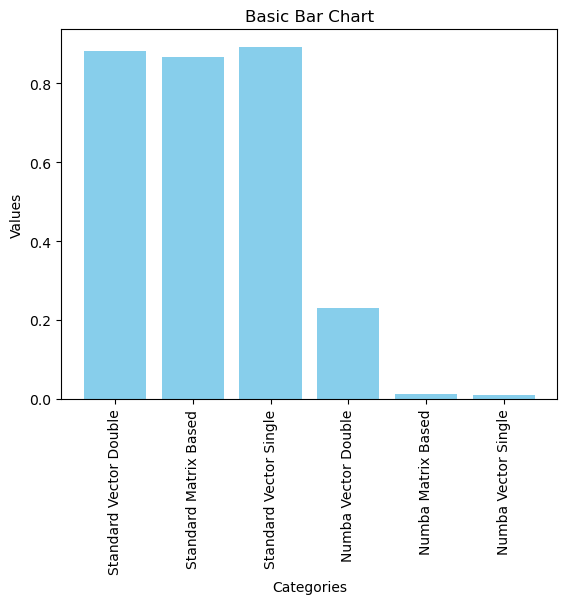

In [13]:
import matplotlib.pyplot as plt

categories = [
    "Standard Vector Double", 
    "Standard Matrix Based", 
    "Standard Vector Single",
    "Numba Vector Double", 
    "Numba Matrix Based", 
    "Numba Vector Single",
]

values = [
    standard_vector_double,
    standard_matrix_based,
    standard_vector_single,
    numba_vector_double,
    numba_matrix_based,
    numba_vector_single,
]

plt.bar(categories, values, color='skyblue')
plt.title('Basic Bar Chart')
plt.xticks(rotation='vertical')
plt.xlabel('Categories')
plt.ylabel('Values')

plt.show()

## Plotting

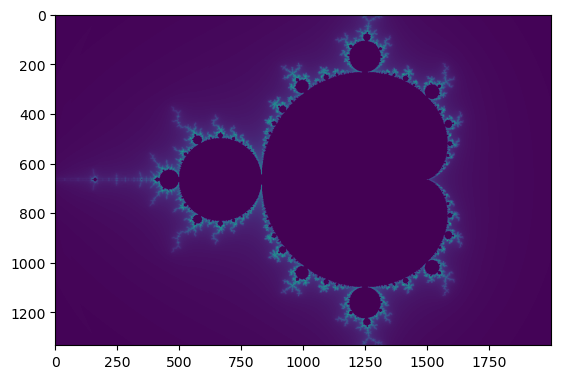

In [33]:
plt.imshow(mat)
plt.show()

In [28]:
from plotly import graph_objects as go

categories = [
    "Vector Double", 
    "Matrix Based", 
    "Vector Single",
]

fig = go.Figure()
fig.add_trace(go.Bar(
    x=categories,
    y=[
        standard_vector_double,
        standard_matrix_based,
        standard_vector_single,
    ],
    name='Standard',
))
fig.add_trace(go.Bar(
    x=categories,
    y=[
        numba_vector_double,
        numba_matrix_based,
        numba_vector_single,
    ],
    name='Numba',
))

# Here we modify the tickangle of the xaxis, resulting in rotated labels.
fig.update_layout(
    barmode='group', 
    xaxis_tickangle=-45,
    yaxis=dict(type="log"),
)
fig.show()

In [38]:
fig = go.Figure()
fig.add_trace(
    go.Heatmap(
        z=mat,
        x=x_vec,
        y=y_vec,
    )
)
fig.show()